# Spectral clustering of the PE-report features

This notebook processes `result/data2_features.csv`, clusters the samples with **spectral clustering**, evaluates the result with standard clustering metrics, and finally maps representative samples of every cluster back to the initial dataset.

| Step | Section | What happens |
| --- | --- | --- |
| 1 | Load | Read the CSV produced by `extract_data2_features.py`. |
| 2 | Process | Turn the JSON-like columns into numeric features, flag incomplete reports. |
| 3 | Feature matrix | Log-transform, winsorise, standardise, one-hot encode the entry-point section. |
| 4 | Spectral clustering | Landmarks → self-tuning affinity → Laplacian spectrum → `SpectralClustering`. |
| 5 | Evaluation | Silhouette, Davies–Bouldin, Calinski–Harabasz, stability (ARI), k-means baseline. |
| 6 | Cluster profiles | What distinguishes each cluster from the dataset as a whole. |
| 7 | Remap representatives | **Option block**: pick representative samples, map them back to the CSV rows, compare. |
| 8 | Findings | Generated summary plus interpretation. |

A full run takes roughly two to three minutes. All tunable values live in the configuration cell below and in the option cell of section 7.

In [1]:
import json
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.linalg import eigh
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_mutual_info_score,
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    pairwise_distances,
    pairwise_distances_argmin,
    silhouette_samples,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

# ---- Configuration ---------------------------------------------------------
DATA_PATH = Path.cwd() / "result" / "data2_features.csv"
REPORT_DIR = Path.cwd() / "sources" / "data2"   # raw text reports (optional, section 7)
RANDOM_STATE = 42

# Processing
WINSOR_LIMITS = (0.01, 0.99)   # per-feature clipping quantiles before scaling
MIN_ENTRY_SHARE = 0.01         # entry-point sections rarer than this are grouped as "other"

# Spectral clustering
N_LANDMARKS = 2_000            # k-means landmarks that stand in for the samples
LOCAL_SCALE_NEIGHBOR = 7       # self-tuning affinity: scale = distance to this neighbour
K_RANGE = range(2, 11)         # candidate numbers of clusters
N_CLUSTERS = None              # None = use the suggestion from section 4.2, or set an int
STABILITY_SEEDS = (1, 2, 3)    # extra landmark seeds used to measure stability
GAP_TOLERANCE = 0.75           # eigengap must reach this share of the largest gap
MIN_STABILITY = 0.80           # minimum mean pairwise ARI for a k to be suggested

# Evaluation
SILHOUETTE_SAMPLE = 6_000      # silhouette is O(n^2), so it is computed on a fixed sample

In [2]:
# Chart style: one light surface, hairline grid, blue = spectral, orange = k-means baseline.
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, NEUTRAL = "#2a78d6", "#eb6834", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "lines.linewidth": 2, "lines.markersize": 6,
    "legend.frameon": False,
})

# Sequential (magnitude) and diverging (below / above a reference) colour scales.
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "sequential_blue", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING = LinearSegmentedColormap.from_list(
    "diverging_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f1a5a4", "#d03b3b"]
)


def annotated_heatmap(ax, table, cmap, vmin, vmax, fmt="{:.0f}"):
    """Draw `table` as a heatmap with the value written in every cell."""
    values = table.to_numpy(dtype=float)
    image = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=40, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    # A thin surface-coloured gap separates the cells instead of borders.
    ax.set_xticks(np.arange(-0.5, table.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, table.shape[0]), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    for (row, col), value in np.ndenumerate(values):
        if np.isfinite(value):
            red, green, blue, _ = image.cmap(image.norm(value))
            dark_cell = 0.2126 * red + 0.7152 * green + 0.0722 * blue < 0.5
            ax.text(col, row, fmt.format(value), ha="center", va="center",
                    fontsize=8, color="white" if dark_cell else INK)
    return image


def format_number(value):
    """Compact, readable number formatting for the comparison tables."""
    if pd.isna(value):
        return "–"
    if abs(value) >= 1_000:
        return f"{value:,.0f}"
    if float(value).is_integer():
        return f"{value:.0f}"
    return f"{value:.3f}"

## 1. Load the dataset

In [3]:
df = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")
display(df.head(3))

Rows: 38,161   Columns: 12


,SourceFile,FileSHA256,FileSize,FileEntropy,NumberOfSections,SectionEntropy,SectionCharacteristics,SizeOfCode,EntryPointSection,ImportedDLLCount,NumberOfImportedFunctions,ImportName
0,0000680b25437e422f261d6f2b1061d033c81b6375ed6e...,0000680b25437e422f261d6f2b1061d033c81b6375ed6e...,2992665,6.580574,11,"[{""name"":"".text"",""value"":6.452086},{""name"":"".i...","[{""name"":"".text"",""value"":1610612768},{""name"":""...",2472448,.itext,24,627,"[""SysFreeString"",""SysReAllocStringLen"",""SysAll..."
1,0000db8949bcf95369d96efbe5cf7fb4c225a19a98cfef...,0000db8949bcf95369d96efbe5cf7fb4c225a19a98cfef...,138405,5.841462,3,"[{""name"":"".text"",""value"":5.734799},{""name"":"".d...","[{""name"":"".text"",""value"":3758096416},{""name"":""...",106496,.text,1,135,"[""EVENT_SINK_GetIDsOfNames"",""ord690"",""_CIcos"",..."
2,00012685e46f01c07ee2245206f8cfa20989fd442eda5f...,00012685e46f01c07ee2245206f8cfa20989fd442eda5f...,1408048,6.798126,5,"[{""name"":"".text"",""value"":6.628891},{""name"":"".r...","[{""name"":"".text"",""value"":1610612768},{""name"":""...",1152512,.text,5,171,"[""CertFreeCertificateContext"",""CertFreeCertifi..."


## 2. Process the raw columns

Three columns hold JSON arrays (`SectionEntropy`, `SectionCharacteristics`, `ImportName`), so they are summarised into numeric features:

- **Section entropy** → mean, standard deviation and maximum over the sections.
- **Section characteristics** → number of executable, writable and simultaneously read-write-execute (RWX) sections, decoded from the PE flag bits.
- **Import names** → number of distinct imported functions. The names themselves are kept for interpreting the clusters later.
- **Code ratio** → `SizeOfCode / FileSize`; values above 1 mean the code section is larger in memory than the file on disk, which is typical for packers.

Reports without section data or without an entry-point section cannot be described by these features, so they are flagged and left out of the clustering (they come back as "not clustered" in section 7).

In [4]:
MEM_EXECUTE, MEM_READ, MEM_WRITE = 0x20000000, 0x40000000, 0x80000000
RWX = MEM_EXECUTE | MEM_READ | MEM_WRITE


def parse_json_list(value):
    """Return the JSON array stored in a CSV cell, or an empty list."""
    if not isinstance(value, str) or not value:
        return []
    try:
        parsed = json.loads(value)
    except json.JSONDecodeError:
        return []
    return parsed if isinstance(parsed, list) else []


def section_values(items):
    """Numeric `value` entries of a parsed section list."""
    values = [pd.to_numeric(item.get("value"), errors="coerce") for item in items if isinstance(item, dict)]
    return np.asarray([value for value in values if pd.notna(value)], dtype=float)


def section_names(items):
    return ", ".join(str(item.get("name")) for item in items if isinstance(item, dict))


entropy_lists = df["SectionEntropy"].map(parse_json_list)
characteristic_lists = df["SectionCharacteristics"].map(parse_json_list)
import_lists = df["ImportName"].map(parse_json_list)

entropy_values = entropy_lists.map(section_values)
flag_values = characteristic_lists.map(lambda items: section_values(items).astype(np.uint32))

features = pd.DataFrame(index=df.index)
for column in ["FileSize", "FileEntropy", "NumberOfSections", "SizeOfCode",
               "ImportedDLLCount", "NumberOfImportedFunctions"]:
    features[column] = pd.to_numeric(df[column], errors="coerce")

features["section_entropy_mean"] = entropy_values.map(lambda v: v.mean() if v.size else np.nan)
features["section_entropy_std"] = entropy_values.map(lambda v: v.std() if v.size else np.nan)
features["section_entropy_max"] = entropy_values.map(lambda v: v.max() if v.size else np.nan)
features["executable_section_count"] = flag_values.map(
    lambda v: float(((v & MEM_EXECUTE) != 0).sum()) if v.size else np.nan)
features["writable_section_count"] = flag_values.map(
    lambda v: float(((v & MEM_WRITE) != 0).sum()) if v.size else np.nan)
features["rwx_section_count"] = flag_values.map(
    lambda v: float(((v & RWX) == RWX).sum()) if v.size else np.nan)
features["size_of_code_ratio"] = (features["SizeOfCode"] / features["FileSize"]).where(features["FileSize"] > 0)
features["import_name_unique_count"] = import_lists.map(lambda names: len(set(names)))

entry_point = df["EntryPointSection"].astype("string").str.strip()
features["EntryPointSection"] = entry_point.where(entry_point.notna() & entry_point.ne(""))
features["section_names"] = entropy_lists.map(section_names)

missing_reasons = pd.DataFrame({
    "no section entropy": features["section_entropy_mean"].isna(),
    "no section characteristics": features["executable_section_count"].isna(),
    "no entry-point section": features["EntryPointSection"].isna(),
})
features["complete"] = ~missing_reasons.any(axis=1)

print(f"Complete reports used for clustering: {features['complete'].sum():,} of {len(features):,}")
print(f"Excluded incomplete reports:          {(~features['complete']).sum():,}")
display(missing_reasons.sum().rename("reports affected").to_frame())

Complete reports used for clustering: 36,657 of 38,161
Excluded incomplete reports:          1,504


,reports affected
no section entropy,538
no section characteristics,176
no entry-point section,1492


## 3. Build the feature matrix

Spectral clustering works on distances between samples, so every feature has to live on a comparable scale:

- **Sizes and counts** are heavy-tailed (a few files are thousands of times larger than the median), so they are `log1p`-transformed.
- Every numeric feature is then **winsorised** at the 1st and 99th percentile and **standardised**, which keeps a handful of extreme files from stretching the scale.
- `EntryPointSection` is categorical with hundreds of rare names. Names that cover at least 1% of the samples get a one-hot column; the rest share one `other` column.

`import_name_unique_count` is left out of the distance on purpose: its rank correlation with `NumberOfImportedFunctions` is above 0.99, so using both would simply count the import volume twice.

In [5]:
LOG_FEATURES = [
    "FileSize", "SizeOfCode", "NumberOfSections", "ImportedDLLCount", "NumberOfImportedFunctions",
    "executable_section_count", "writable_section_count", "rwx_section_count",
]
LINEAR_FEATURES = [
    "FileEntropy", "section_entropy_mean", "section_entropy_std", "section_entropy_max", "size_of_code_ratio",
]

model_df = features.loc[features["complete"]].copy()

redundancy = model_df["NumberOfImportedFunctions"].corr(model_df["import_name_unique_count"], method="spearman")
print(f"Spearman correlation, imported functions vs unique import names: {redundancy:.4f}")

numeric = pd.DataFrame(index=model_df.index)
for column in LOG_FEATURES:
    numeric[f"log1p_{column}"] = np.log1p(model_df[column].clip(lower=0))
for column in LINEAR_FEATURES:
    numeric[column] = model_df[column]

lower, upper = numeric.quantile(WINSOR_LIMITS[0]), numeric.quantile(WINSOR_LIMITS[1])
numeric = numeric.clip(lower, upper, axis=1)
X_numeric = StandardScaler().fit_transform(numeric)

entry_counts = model_df["EntryPointSection"].value_counts()
common_entries = entry_counts[entry_counts >= MIN_ENTRY_SHARE * len(model_df)].index
model_df["entry_group"] = model_df["EntryPointSection"].where(
    model_df["EntryPointSection"].isin(common_entries), "other")
entry_one_hot = pd.get_dummies(model_df["entry_group"], prefix="entry", dtype=float)

X = np.hstack([X_numeric, entry_one_hot.to_numpy()])
feature_names = list(numeric.columns) + list(entry_one_hot.columns)

assert np.isfinite(X).all()
print(f"Feature matrix: {X.shape[0]:,} samples x {X.shape[1]} features "
      f"({X_numeric.shape[1]} numeric + {entry_one_hot.shape[1]} entry-point columns)")
print("Entry-point groups:", ", ".join(entry_one_hot.columns.str.removeprefix("entry_")))

Spearman correlation, imported functions vs unique import names: 0.9995
Feature matrix: 36,657 samples x 21 features (13 numeric + 8 entry-point columns)
Entry-point groups: .data, .itext, .reloc, .text, CODE, UPX0, UPX1, other


## 4. Spectral clustering

Spectral clustering treats the samples as nodes of a similarity graph and looks for groups that are strongly connected inside and weakly connected to the rest. It does so by embedding the nodes with the first eigenvectors of the graph Laplacian and running k-means in that embedding. Unlike plain k-means it does not assume round, equally sized clusters.

**Why landmarks.** A full affinity matrix for 36,657 samples would need about 10 GB. A sparse nearest-neighbour graph fits in memory, but on this data it breaks into hundreds of tiny islands of near-identical samples, and the spectrum then spends its first eigenvectors on groups of 50–100 files. The notebook therefore uses the landmark variant of spectral clustering (KASP, Yan, Huang & Jordan 2009):

1. Compress the samples into `N_LANDMARKS` k-means centroids.
2. Build a dense **self-tuning affinity** between the landmarks (Zelnik-Manor & Perona 2004): $A_{ij} = \exp\!\left(-d_{ij}^2 / (\sigma_i \sigma_j)\right)$, where $\sigma_i$ is the distance from landmark $i$ to its 7th nearest landmark. The local scale adapts to dense and sparse regions, so no global bandwidth has to be tuned.
3. Run `sklearn.cluster.SpectralClustering` on that affinity.
4. Every sample inherits the cluster of its landmark.

### 4.1 Landmarks, affinity and the candidate partitions

In [6]:
def fit_landmarks(X, n_landmarks, seed):
    """Compress the samples into k-means centroids; return centroids and each sample's landmark."""
    model = KMeans(n_clusters=n_landmarks, n_init=1, max_iter=50, random_state=seed).fit(X)
    return model.cluster_centers_, model.labels_


def self_tuning_affinity(points, neighbor=7):
    """Dense Gaussian affinity with a per-point bandwidth (distance to the `neighbor`-th point)."""
    distances = pairwise_distances(points)
    sigma = np.maximum(np.sort(distances, axis=1)[:, neighbor], 1e-12)  # column 0 is the point itself
    affinity = np.exp(-(distances ** 2) / np.outer(sigma, sigma))
    np.fill_diagonal(affinity, 0.0)
    return affinity


def laplacian_eigenvalues(affinity, n_values):
    """Smallest eigenvalues of the symmetric normalised Laplacian  L = I - D^-1/2 A D^-1/2."""
    inv_sqrt_degree = 1.0 / np.sqrt(affinity.sum(axis=1))
    laplacian = np.eye(len(affinity)) - inv_sqrt_degree[:, None] * affinity * inv_sqrt_degree[None, :]
    return eigh(laplacian, eigvals_only=True, subset_by_index=[0, n_values - 1])


def spectral_partition(affinity, landmark_of_sample, n_clusters):
    """Spectral clustering of the landmarks, propagated to the samples."""
    model = SpectralClustering(
        n_clusters=n_clusters,
        affinity="precomputed",
        assign_labels="kmeans",
        n_init=20,
        random_state=RANDOM_STATE,
    )
    return model.fit_predict(affinity)[landmark_of_sample]


# One landmark set per seed. The first seed gives the reported clustering,
# the others only measure how much the result depends on the landmarks.
spectral_runs = {}
landmark_sets = {}
for seed in (RANDOM_STATE, *STABILITY_SEEDS):
    centers, landmark_of_sample = fit_landmarks(X, N_LANDMARKS, seed)
    affinity = self_tuning_affinity(centers, LOCAL_SCALE_NEIGHBOR)
    landmark_sets[seed] = (centers, landmark_of_sample, affinity)
    for k in K_RANGE:
        spectral_runs[(seed, k)] = spectral_partition(affinity, landmark_of_sample, k)
    print(f"seed {seed}: {N_LANDMARKS:,} landmarks, {len(K_RANGE)} partitions")

centers, landmark_of_sample, affinity = landmark_sets[RANDOM_STATE]
landmark_sizes = np.bincount(landmark_of_sample, minlength=N_LANDMARKS)
print(f"\nSamples per landmark: median {np.median(landmark_sizes):.0f}, max {landmark_sizes.max():,}")

seed 42: 2,000 landmarks, 9 partitions
seed 1: 2,000 landmarks, 9 partitions
seed 2: 2,000 landmarks, 9 partitions
seed 3: 2,000 landmarks, 9 partitions

Samples per landmark: median 7, max 1,304


### 4.2 How many clusters?

Two independent signals are used, plus the usual internal metrics for context:

- **Eigengap.** If the graph had $k$ perfectly separated groups, the Laplacian would have exactly $k$ zero eigenvalues. A large jump between $\lambda_k$ and $\lambda_{k+1}$ therefore supports $k$ clusters.
- **Stability.** The whole pipeline is repeated with different landmark seeds. The mean pairwise Adjusted Rand Index (ARI) between those runs is 1 when the partition does not depend on the seed and near 0 when it is arbitrary.

A k-means baseline on the same feature matrix is computed alongside for comparison.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
silhouette_index = rng.choice(len(X), size=min(SILHOUETTE_SAMPLE, len(X)), replace=False)


def internal_metrics(labels):
    """The three standard internal metrics, measured in the scaled feature space."""
    return {
        "silhouette": silhouette_score(X[silhouette_index], labels[silhouette_index]),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
    }


def mean_pairwise_ari(partitions):
    scores = [adjusted_rand_score(a, b) for i, a in enumerate(partitions) for b in partitions[i + 1:]]
    return float(np.mean(scores))


eigenvalues = laplacian_eigenvalues(affinity, max(K_RANGE) + 6)

kmeans_runs = {}
rows = []
for k in K_RANGE:
    kmeans_runs[k] = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    spectral = internal_metrics(spectral_runs[(RANDOM_STATE, k)])
    baseline = internal_metrics(kmeans_runs[k])
    sizes = np.bincount(spectral_runs[(RANDOM_STATE, k)])
    rows.append({
        "k": k,
        "eigengap": eigenvalues[k] - eigenvalues[k - 1],
        "stability_ari": mean_pairwise_ari(
            [spectral_runs[(seed, k)] for seed in (RANDOM_STATE, *STABILITY_SEEDS)]),
        **{f"spectral_{name}": value for name, value in spectral.items()},
        **{f"kmeans_{name}": value for name, value in baseline.items()},
        "smallest_cluster_share": sizes.min() / sizes.sum(),
    })

sweep = pd.DataFrame(rows).set_index("k")
display(sweep.round(3))

,eigengap,stability_ari,spectral_silhouette,spectral_davies_bouldin,spectral_calinski_harabasz,kmeans_silhouette,kmeans_davies_bouldin,kmeans_calinski_harabasz,smallest_cluster_share
k,,,,,,,,,
2,0.063,0.946,0.179,1.343,3673.062,0.194,1.998,7469.892,0.080
3,0.007,0.445,0.148,1.012,2639.308,0.211,1.775,7633.247,0.035
4,0.041,0.911,0.159,1.828,3730.103,0.223,1.730,6720.133,0.035
5,0.063,0.867,0.161,1.710,4054.668,0.179,1.714,6184.638,0.030
6,0.030,0.814,0.092,1.815,3713.631,0.189,1.618,5811.746,0.031
7,0.025,0.610,0.101,1.600,3536.391,0.181,1.804,5442.088,0.016
8,0.006,0.433,0.089,1.639,2870.521,0.198,1.639,5353.240,0.016
9,0.020,0.558,0.082,1.654,3302.127,0.224,1.548,5233.051,0.016
10,0.023,0.582,0.062,1.769,2666.475,0.228,1.523,4995.408,0.016


k supported by eigengap and stability: [2, 5]
Suggested k = 5; using k = 5


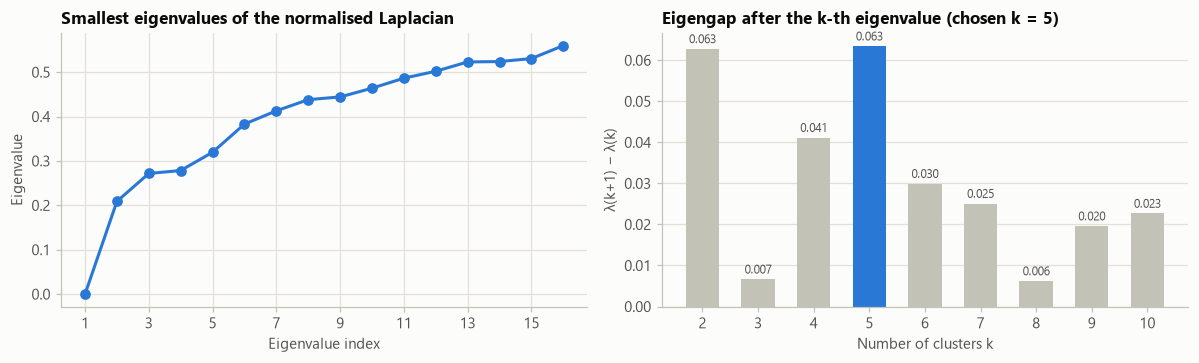

In [8]:
# Suggested k: the finest partition whose eigengap is close to the largest one and that is stable.
supported = sweep[(sweep["eigengap"] >= GAP_TOLERANCE * sweep["eigengap"].max())
                  & (sweep["stability_ari"] >= MIN_STABILITY)]
suggested_k = int(supported.index.max()) if len(supported) else int(sweep["stability_ari"].idxmax())
n_clusters = int(N_CLUSTERS) if N_CLUSTERS is not None else suggested_k

print(f"k supported by eigengap and stability: {list(supported.index)}")
print(f"Suggested k = {suggested_k}; using k = {n_clusters}")

fig, (ax_spectrum, ax_gap) = plt.subplots(1, 2, figsize=(11, 3.4))

order = np.arange(1, len(eigenvalues) + 1)
ax_spectrum.plot(order, eigenvalues, color=BLUE, marker="o")
ax_spectrum.set_title("Smallest eigenvalues of the normalised Laplacian")
ax_spectrum.set_xlabel("Eigenvalue index")
ax_spectrum.set_ylabel("Eigenvalue")
ax_spectrum.set_xticks(order[::2])

bar_colors = [BLUE if k == n_clusters else NEUTRAL for k in sweep.index]
bars = ax_gap.bar(sweep.index, sweep["eigengap"], color=bar_colors, width=0.6)
ax_gap.bar_label(bars, labels=[f"{gap:.3f}" for gap in sweep["eigengap"]], padding=2, fontsize=8, color=INK_2)
ax_gap.set_title(f"Eigengap after the k-th eigenvalue (chosen k = {n_clusters})")
ax_gap.set_xlabel("Number of clusters k")
ax_gap.set_ylabel("λ(k+1) − λ(k)")
ax_gap.set_xticks(list(sweep.index))
ax_gap.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

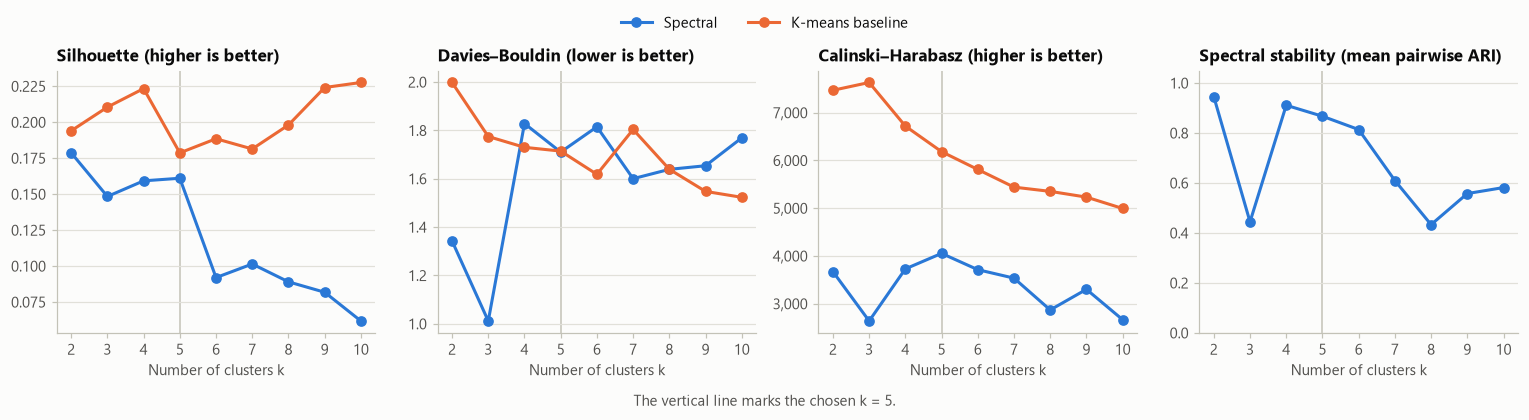

In [9]:
panels = [
    ("silhouette", "Silhouette (higher is better)"),
    ("davies_bouldin", "Davies–Bouldin (lower is better)"),
    ("calinski_harabasz", "Calinski–Harabasz (higher is better)"),
]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for ax, (metric, title) in zip(axes, panels):
    ax.plot(sweep.index, sweep[f"spectral_{metric}"], color=BLUE, marker="o", label="Spectral")
    ax.plot(sweep.index, sweep[f"kmeans_{metric}"], color=ORANGE, marker="o", label="K-means baseline")
    ax.set_title(title)
axes[2].yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")

axes[3].plot(sweep.index, sweep["stability_ari"], color=BLUE, marker="o")
axes[3].set_title("Spectral stability (mean pairwise ARI)")
axes[3].set_ylim(0, 1.05)

for ax in axes:
    ax.axvline(n_clusters, color=AXIS, linewidth=1, zorder=0)
    ax.set_xlabel("Number of clusters k")
    ax.set_xticks(list(sweep.index))
    ax.grid(axis="x", visible=False)

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.08))
fig.text(0.5, -0.03, f"The vertical line marks the chosen k = {n_clusters}.", ha="center", color=INK_2)
plt.tight_layout()
plt.show()

### 4.3 Final clustering

The partition for the chosen `k` is taken from the main landmark seed. Clusters are renumbered by size, so cluster 0 is always the largest.

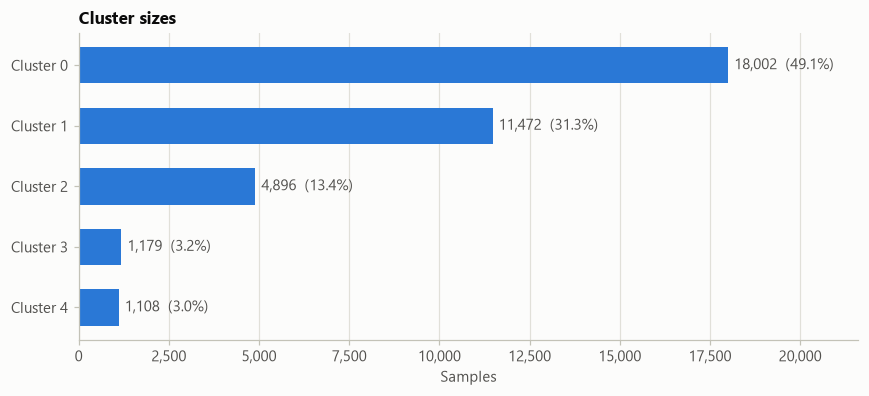

In [10]:
raw_labels = spectral_runs[(RANDOM_STATE, n_clusters)]
size_order = np.argsort(-np.bincount(raw_labels, minlength=n_clusters))
relabel = np.empty(n_clusters, dtype=int)
relabel[size_order] = np.arange(n_clusters)

labels = relabel[raw_labels]
model_df["cluster"] = labels
cluster_ids = list(range(n_clusters))
cluster_sizes = model_df["cluster"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 0.5 * n_clusters + 1.2))
bars = ax.barh([f"Cluster {c}" for c in cluster_ids], cluster_sizes.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{size:,}  ({size / len(labels):.1%})" for size in cluster_sizes.values],
             padding=4, color=INK_2)
ax.invert_yaxis()
ax.set_title("Cluster sizes")
ax.set_xlabel("Samples")
ax.set_xlim(0, cluster_sizes.max() * 1.2)
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 5. Evaluate the clustering quality

There are no ground-truth family labels in the dataset, so the evaluation relies on **internal** metrics and on **stability**:

| Metric | Range | Reads as |
| --- | --- | --- |
| Silhouette coefficient | −1 … 1 | How much closer a sample is to its own cluster than to the nearest other one. Higher is better; near 0 means overlapping clusters. |
| Davies–Bouldin index | 0 … ∞ | Average similarity of each cluster to its most similar neighbour. Lower is better. |
| Calinski–Harabasz index | 0 … ∞ | Between-cluster over within-cluster variance. Higher is better; only comparable for the same data. |
| Stability (ARI) | ≈0 … 1 | Agreement between repeated runs with different seeds. 1 means the same partition every time. |

All three internal metrics are computed in the scaled feature space with Euclidean distance, and all three reward compact, round clusters, which is exactly what k-means optimises. Spectral clustering optimises graph connectivity instead, so a k-means baseline with the same `k` is shown as a reference point, not as a contest that spectral clustering is expected to win.

In [11]:
kmeans_labels = kmeans_runs[n_clusters]
kmeans_seed_runs = [kmeans_labels] + [
    KMeans(n_clusters=n_clusters, n_init=10, random_state=seed).fit_predict(X) for seed in STABILITY_SEEDS
]
spectral_seed_runs = [spectral_runs[(seed, n_clusters)] for seed in (RANDOM_STATE, *STABILITY_SEEDS)]


def evaluation_column(partition, seed_runs):
    sizes = np.bincount(partition)
    return {
        "Silhouette (sample)": silhouette_score(X[silhouette_index], partition[silhouette_index]),
        "Davies–Bouldin": davies_bouldin_score(X, partition),
        "Calinski–Harabasz": calinski_harabasz_score(X, partition),
        "Stability (mean pairwise ARI)": mean_pairwise_ari(seed_runs),
        "Smallest cluster share": sizes.min() / sizes.sum(),
        "Largest cluster share": sizes.max() / sizes.sum(),
    }


evaluation = pd.DataFrame({
    "Spectral": evaluation_column(labels, spectral_seed_runs),
    "K-means baseline": evaluation_column(kmeans_labels, kmeans_seed_runs),
})
evaluation["Better when"] = ["higher", "lower", "higher", "higher", "–", "–"]

agreement_ari = adjusted_rand_score(labels, kmeans_labels)
agreement_ami = adjusted_mutual_info_score(labels, kmeans_labels)

print(f"Number of clusters: {n_clusters}")
display(evaluation.round(4))
print(f"Agreement between spectral and k-means partitions: ARI = {agreement_ari:.3f}, AMI = {agreement_ami:.3f}")

Number of clusters: 5


,Spectral,K-means baseline,Better when
Silhouette (sample),0.1611,0.1787,higher
Davies–Bouldin,1.7104,1.7144,lower
Calinski–Harabasz,4054.6678,6184.6382,higher
Stability (mean pairwise ARI),0.8672,0.8904,higher
Smallest cluster share,0.0302,0.0706,–
Largest cluster share,0.4911,0.3221,–


Agreement between spectral and k-means partitions: ARI = 0.506, AMI = 0.588


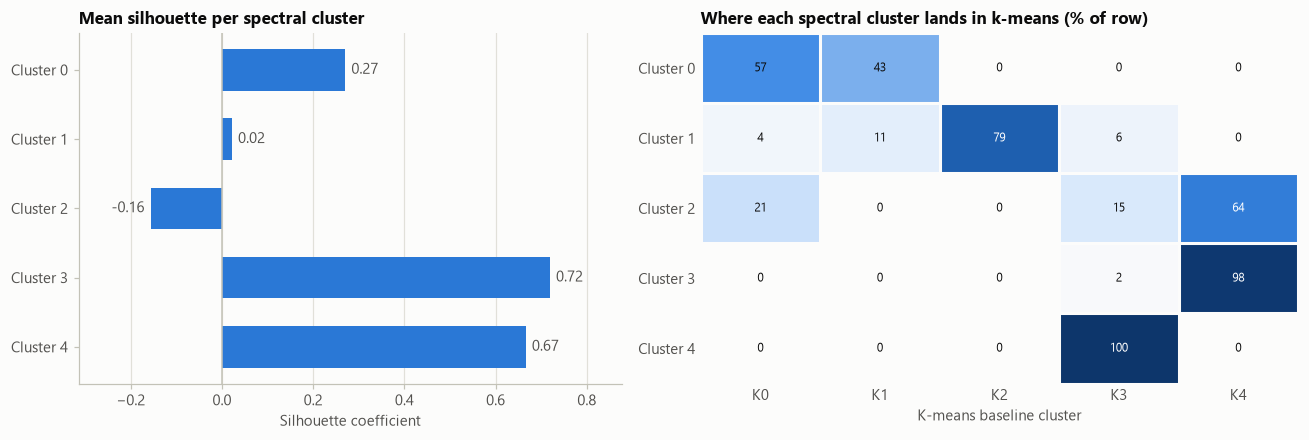

,samples,mean silhouette,share with negative silhouette,closest other cluster
cluster,,,,
0,18002,0.270,0.010,Cluster 1
1,11472,0.022,0.351,Cluster 0
2,4896,-0.157,0.819,Cluster 3
3,1179,0.719,0.000,Cluster 4
4,1108,0.666,0.005,Cluster 3


In [12]:
sample_silhouettes = pd.Series(
    silhouette_samples(X[silhouette_index], labels[silhouette_index]),
    index=labels[silhouette_index],
)
silhouette_by_cluster = sample_silhouettes.groupby(level=0).mean().reindex(cluster_ids)
negative_share = sample_silhouettes.lt(0).groupby(level=0).mean().reindex(cluster_ids)

# For every cluster: which other cluster its members are closest to on average.
sample_distances = pairwise_distances(X[silhouette_index])
mean_distance_to = pd.DataFrame(
    {c: sample_distances[:, labels[silhouette_index] == c].mean(axis=1) for c in cluster_ids},
    index=labels[silhouette_index],
).groupby(level=0).mean()
closest_other = pd.Series({
    c: f"Cluster {mean_distance_to.loc[c].drop(c).idxmin()}" for c in cluster_ids
})

# How the spectral clusters map onto the k-means clusters (row shares).
overlap = pd.crosstab(pd.Series(labels, name="spectral"), pd.Series(kmeans_labels, name="k-means"),
                      normalize="index") * 100
overlap.index = [f"Cluster {c}" for c in overlap.index]
overlap.columns = [f"K{c}" for c in overlap.columns]

fig, (ax_sil, ax_overlap) = plt.subplots(1, 2, figsize=(12, 0.5 * n_clusters + 1.6),
                                        gridspec_kw={"width_ratios": [1, 1.1]})

bars = ax_sil.barh([f"Cluster {c}" for c in cluster_ids], silhouette_by_cluster.values, color=BLUE, height=0.6)
ax_sil.bar_label(bars, labels=[f"{value:.2f}" for value in silhouette_by_cluster.values], padding=4, color=INK_2)
ax_sil.axvline(0, color=AXIS, linewidth=1)
ax_sil.invert_yaxis()
ax_sil.set_title("Mean silhouette per spectral cluster")
ax_sil.set_xlabel("Silhouette coefficient")
ax_sil.margins(x=0.18)
ax_sil.grid(axis="y", visible=False)

annotated_heatmap(ax_overlap, overlap, SEQUENTIAL, 0, 100)
ax_overlap.set_title("Where each spectral cluster lands in k-means (% of row)")
ax_overlap.set_xlabel("K-means baseline cluster")
ax_overlap.tick_params(axis="x", rotation=0)
plt.setp(ax_overlap.get_xticklabels(), ha="center")

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "samples": cluster_sizes,
    "mean silhouette": silhouette_by_cluster.round(3),
    "share with negative silhouette": negative_share.round(3),
    "closest other cluster": closest_other,
}).rename_axis("cluster"))

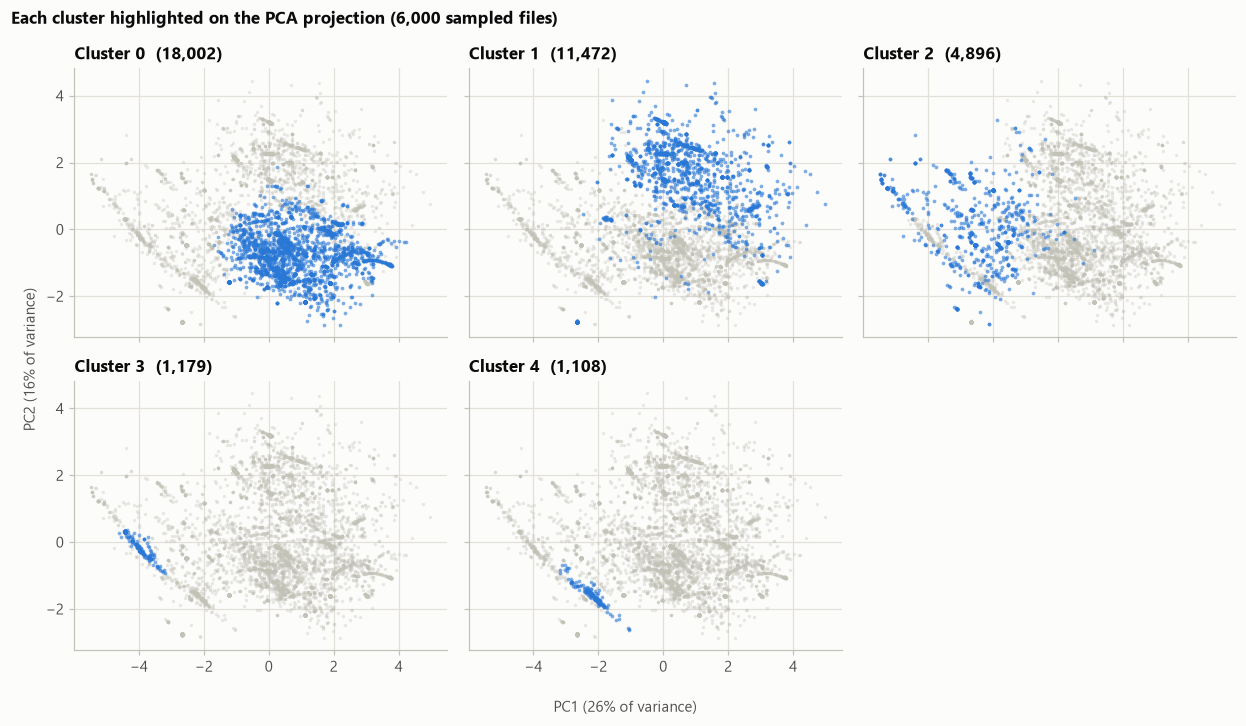

In [13]:
# 2-D view: PCA of the feature matrix, one panel per cluster so every cluster is readable on its own.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
projection = pca.fit_transform(X)[silhouette_index]
projection_labels = labels[silhouette_index]

n_columns = min(n_clusters, 3)
n_rows = int(np.ceil(n_clusters / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(3.8 * n_columns, 3.3 * n_rows),
                         sharex=True, sharey=True, squeeze=False)

for ax, cluster in zip(axes.ravel(), cluster_ids):
    members = projection_labels == cluster
    ax.scatter(projection[~members, 0], projection[~members, 1], s=5, color=NEUTRAL, alpha=0.35, linewidths=0)
    ax.scatter(projection[members, 0], projection[members, 1], s=6, color=BLUE, alpha=0.6, linewidths=0)
    ax.set_title(f"Cluster {cluster}  ({cluster_sizes[cluster]:,})")
for ax in axes.ravel()[n_clusters:]:
    ax.set_visible(False)

fig.supxlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)", color=INK_2, fontsize=10)
fig.supylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)", color=INK_2, fontsize=10)
fig.suptitle(f"Each cluster highlighted on the PCA projection ({len(projection):,} sampled files)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

## 6. Cluster profiles

To see what each cluster *means*, the clusters are described with the raw, interpretable features and compared with the **initial dataset** (all rows of the CSV, including the incomplete reports that were not clustered).

The comparison uses a **percentile shift**: where the cluster's median sits in the distribution of the whole dataset, minus where the dataset's own median sits. `+40` means the typical member of the cluster is 40 percentile points above the typical file of the dataset; `0` means no difference. Unlike a z-score it is not distorted by the extreme outliers in the size and count features.

Feature medians


,Initial dataset,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4
File size,"555,520","1,043,398","594,756","92,646","45,056","847,360"
File entropy,6.531,6.608,7.187,4.882,5.442,7.661
Sections,5,6,3,3,3,3
Section entropy (mean),4.641,4.856,4.737,3.350,3.144,3.904
Section entropy (std),2.079,1.995,2.231,1.972,2.343,3.124
Section entropy (max),6.661,6.658,7.665,5.808,5.603,7.695
Executable sections,1,1,2,1,1,1
Writable sections,2,2,3,1,0,0
RWX sections,0,0,2,0,0,0
Size of code,"147,456","182,272","101,376","43,008","39,936","830,976"


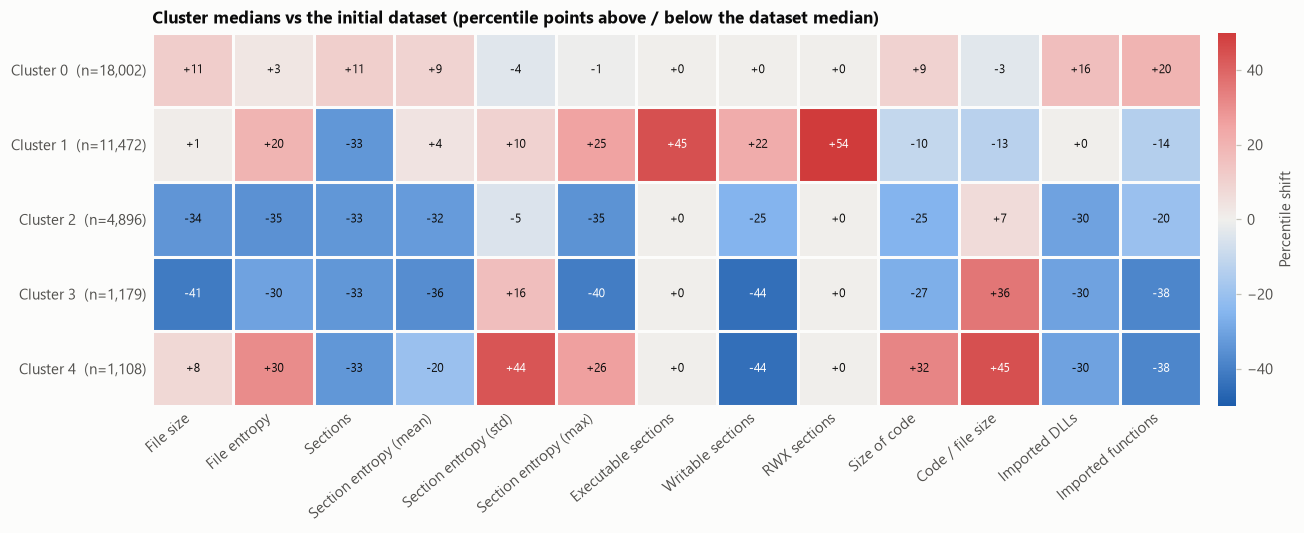

In [14]:
PROFILE_FEATURES = {
    "FileSize": "File size",
    "FileEntropy": "File entropy",
    "NumberOfSections": "Sections",
    "section_entropy_mean": "Section entropy (mean)",
    "section_entropy_std": "Section entropy (std)",
    "section_entropy_max": "Section entropy (max)",
    "executable_section_count": "Executable sections",
    "writable_section_count": "Writable sections",
    "rwx_section_count": "RWX sections",
    "SizeOfCode": "Size of code",
    "size_of_code_ratio": "Code / file size",
    "ImportedDLLCount": "Imported DLLs",
    "NumberOfImportedFunctions": "Imported functions",
}
profile_columns = list(PROFILE_FEATURES)

# Reference distributions come from the initial dataset (all CSV rows with a value).
reference_sorted = {column: np.sort(features[column].dropna().to_numpy()) for column in profile_columns}
dataset_median = features[profile_columns].median()
dataset_quartiles = features[profile_columns].quantile([0.25, 0.75])


def dataset_percentile(column, values):
    """Mid-rank percentile (0-100) of `values` within the initial dataset's distribution."""
    reference = reference_sorted[column]
    values = np.asarray(values, dtype=float)
    below = np.searchsorted(reference, values, side="left")
    up_to = np.searchsorted(reference, values, side="right")
    return 100 * (below + up_to) / (2 * len(reference))


def percentile_shift(table):
    """Percentile points above (+) or below (-) the dataset median, per feature column."""
    return pd.DataFrame({
        column: dataset_percentile(column, table[column]) - dataset_percentile(column, [dataset_median[column]])[0]
        for column in profile_columns
    }, index=table.index)


cluster_median = model_df.groupby("cluster")[profile_columns].median()
median_shift = percentile_shift(cluster_median)

median_table = pd.concat([dataset_median.rename("initial dataset").to_frame().T, cluster_median])
median_table.index = ["Initial dataset"] + [f"Cluster {c}" for c in cluster_median.index]
print("Feature medians")
display(median_table.rename(columns=PROFILE_FEATURES).map(format_number).T)

heatmap_table = median_shift.rename(columns=PROFILE_FEATURES)
heatmap_table.index = [f"Cluster {c}  (n={cluster_sizes[c]:,})" for c in heatmap_table.index]

fig, ax = plt.subplots(figsize=(12, 0.55 * n_clusters + 2.2))
image = annotated_heatmap(ax, heatmap_table, DIVERGING, -50, 50, fmt="{:+.0f}")
ax.set_title("Cluster medians vs the initial dataset (percentile points above / below the dataset median)")
colorbar = fig.colorbar(image, ax=ax, pad=0.015, fraction=0.03)
colorbar.outline.set_visible(False)
colorbar.set_label("Percentile shift", color=INK_2)
plt.tight_layout()
plt.show()

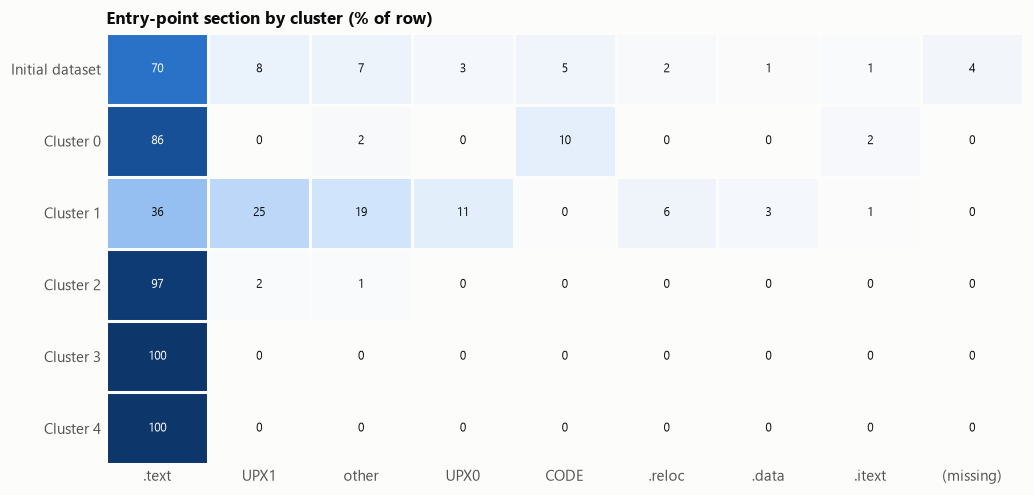

In [15]:
# Entry-point section: share of each group per cluster, next to the initial dataset.
dataset_entry_group = features["EntryPointSection"].where(
    features["EntryPointSection"].isin(common_entries), "other"
).where(features["EntryPointSection"].notna(), "(missing)")

entry_share = pd.crosstab(model_df["cluster"], model_df["entry_group"], normalize="index") * 100
entry_share.index = [f"Cluster {c}" for c in entry_share.index]
entry_table = pd.concat([
    (dataset_entry_group.value_counts(normalize=True) * 100).rename("Initial dataset").to_frame().T,
    entry_share,
]).fillna(0.0)
entry_table = entry_table[entry_table.drop(index="Initial dataset").max().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9.5, 0.5 * (n_clusters + 1) + 1.6))
annotated_heatmap(ax, entry_table, SEQUENTIAL, 0, 100)
ax.set_title("Entry-point section by cluster (% of row)")
plt.setp(ax.get_xticklabels(), rotation=0, ha="center")
plt.tight_layout()
plt.show()

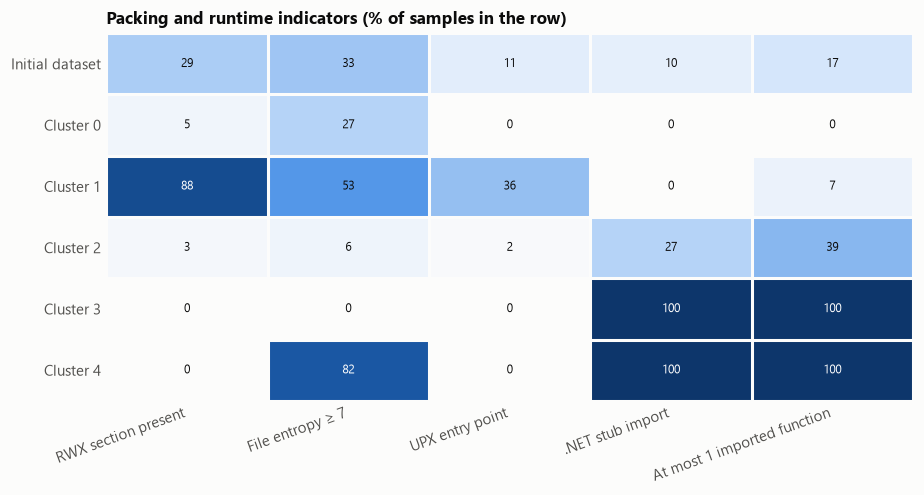

In [16]:
# Simple packing / runtime indicators, as the share of samples that show them.
dotnet_stub = import_lists.map(lambda names: "_CorExeMain" in names or "_CorDllMain" in names)
indicators = pd.DataFrame({
    "RWX section present": features["rwx_section_count"] > 0,
    "File entropy ≥ 7": features["FileEntropy"] >= 7,
    "UPX entry point": features["EntryPointSection"].isin(["UPX0", "UPX1"]),
    ".NET stub import": dotnet_stub,
    "At most 1 imported function": features["NumberOfImportedFunctions"] <= 1,
})
indicator_by_cluster = indicators.loc[model_df.index].groupby(labels).mean()
indicator_by_cluster.index = [f"Cluster {c}" for c in indicator_by_cluster.index]
indicator_table = pd.concat([indicators.mean().rename("Initial dataset").to_frame().T, indicator_by_cluster]) * 100

fig, ax = plt.subplots(figsize=(8.5, 0.5 * (n_clusters + 1) + 1.6))
annotated_heatmap(ax, indicator_table, SEQUENTIAL, 0, 100)
ax.set_title("Packing and runtime indicators (% of samples in the row)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [17]:
# Imports that are much more common inside a cluster than in the rest of the clustered data.
def characteristic_imports(labels, import_lists, top_n=6, min_prevalence=0.15):
    counts = {cluster: Counter() for cluster in np.unique(labels)}
    for names, cluster in zip(import_lists, labels):
        counts[cluster].update(set(names))
    total = sum(counts.values(), Counter())
    sizes = pd.Series(labels).value_counts()

    rows = []
    for cluster, counter in counts.items():
        inside = pd.Series(counter, dtype=float) / sizes[cluster]
        outside = (pd.Series(total, dtype=float).reindex(inside.index) - inside * sizes[cluster]) \
            / (len(labels) - sizes[cluster])
        lift = (inside - outside)[inside >= min_prevalence].sort_index().nlargest(top_n)
        lift = lift[lift > 0.05]
        rows.append({
            "cluster": cluster,
            "over-represented imports (share in cluster / share elsewhere)": "; ".join(
                f"{name} ({inside[name]:.0%} / {outside[name]:.0%})" for name in lift.index) or "(none)",
        })
    return pd.DataFrame(rows).set_index("cluster").sort_index()


import_profile = characteristic_imports(labels, import_lists.loc[model_df.index])
with pd.option_context("display.max_colwidth", None):
    display(import_profile)

,over-represented imports (share in cluster / share elsewhere)
cluster,
0,CloseHandle (85% / 26%); GetLastError (83% / 24%); GetCurrentProcess (78% / 21%); WriteFile (74% / 19%); GetCurrentThreadId (76% / 21%); LeaveCriticalSection (70% / 16%)
1,LoadLibraryA (56% / 44%); atoi (16% / 5%); wsprintfA (20% / 13%); EVENT_SINK_QueryInterface (15% / 10%); EVENT_SINK_Release (15% / 10%); EVENT_SINK_AddRef (15% / 10%)
2,_CorExeMain (18% / 6%); ord100 (21% / 10%); __vbaExceptHandler (21% / 10%); ord594 (19% / 9%); DllFunctionCall (20% / 10%); EVENT_SINK_AddRef (20% / 10%)
3,_CorExeMain (62% / 6%); _CorDllMain (38% / 1%)
4,_CorExeMain (98% / 5%)


## 7. Remap representative samples to the initial dataset

A cluster number says little on its own. This section picks a few **real samples** that stand for each cluster, looks them up in the initial dataset (the original CSV rows, and optionally the raw text report), and compares them with both their cluster and the dataset as a whole.

The cell below is the option block; change it and re-run from here.

| Option | Meaning |
| --- | --- |
| `N_REPRESENTATIVES` | How many samples to show per cluster. |
| `REPRESENTATIVE_METHOD` | `"central"`: the most typical members, i.e. those with the smallest average distance to the rest of their cluster (the first one is the **medoid**). `"diverse"`: the cluster is split into `N_REPRESENTATIVES` sub-groups and the member nearest to each sub-group centre is taken, which shows the spread inside the cluster. |
| `RAW_REPORT_LINES` | If greater than 0, print that many lines of the raw report of each cluster's first representative from `sources/data2`. |

In [18]:
# ---- Options ---------------------------------------------------------------
N_REPRESENTATIVES = 3
REPRESENTATIVE_METHOD = "central"   # "central" or "diverse"
RAW_REPORT_LINES = 0                # e.g. 25 to preview the raw reports

In [19]:
def select_representatives(X, labels, n_per_cluster=3, method="central", seed=RANDOM_STATE):
    """Pick real samples that stand for each cluster; returns positions into X."""
    rng = np.random.default_rng(seed)
    picks = []
    for cluster in np.unique(labels):
        members = np.flatnonzero(labels == cluster)
        Xc = X[members]
        n_picks = min(n_per_cluster, len(members))

        if method == "central":
            # Average distance to (a sample of) the other members; the minimum is the medoid.
            reference = Xc[rng.choice(len(Xc), size=min(len(Xc), 2_000), replace=False)]
            mean_distance = pairwise_distances(Xc, reference).mean(axis=1)
            chosen, seen = [], set()
            for candidate in np.argsort(mean_distance):
                key = Xc[candidate].tobytes()       # skip exact duplicates of an earlier pick
                if key not in seen:
                    seen.add(key)
                    chosen.append(candidate)
                if len(chosen) == n_picks:
                    break
            roles = ["medoid"] + [f"central #{rank}" for rank in range(2, len(chosen) + 1)]
        elif method == "diverse":
            sub_model = KMeans(n_clusters=n_picks, n_init=5, random_state=seed).fit(Xc)
            shares = np.bincount(sub_model.labels_, minlength=n_picks) / len(Xc)
            by_size = np.argsort(-shares)
            chosen = pairwise_distances_argmin(sub_model.cluster_centers_[by_size], Xc)
            roles = [f"sub-group, {share:.0%} of cluster" for share in shares[by_size]]
        else:
            raise ValueError(f"Unknown method: {method!r}")

        for rank, (candidate, role) in enumerate(zip(chosen, roles), start=1):
            picks.append({"cluster": cluster, "rank": rank, "role": role, "position": members[candidate]})
    return pd.DataFrame(picks)


picks = select_representatives(X, labels, N_REPRESENTATIVES, REPRESENTATIVE_METHOD)
picks["row_id"] = model_df.index[picks["position"]]          # row number in data2_features.csv
picks["label"] = [f"C{c} · rep {r}" for c, r in zip(picks["cluster"], picks["rank"])]

# Remap: look the selected samples up in the initial dataset.
representatives = picks.join(df, on="row_id").join(
    features[["section_names"] + [c for c in profile_columns if c not in df.columns]], on="row_id")

preview = representatives[[
    "cluster", "role", "row_id", "FileSHA256", "FileSize", "FileEntropy", "NumberOfSections",
    "SizeOfCode", "EntryPointSection", "ImportedDLLCount", "NumberOfImportedFunctions", "section_names",
]].copy()
preview["FileSHA256"] = preview["FileSHA256"].str[:16] + "…"
preview["first imports"] = import_lists.loc[representatives["row_id"]].map(
    lambda names: ", ".join(names[:5]) + (" …" if len(names) > 5 else "")).to_numpy()

print(f"Method: {REPRESENTATIVE_METHOD}; {N_REPRESENTATIVES} representative(s) per cluster")
with pd.option_context("display.max_colwidth", 70, "display.max_columns", None):
    display(preview.set_index(["cluster", "role"]))

Method: central; 3 representative(s) per cluster


row_id         FileSHA256  FileSize  FileEntropy  \
cluster role                                                           
0       medoid       28158  bacf49519992d3ba…   1288192     6.468614   
        central #2   27159  b485cfd9041a4f01…   1320448     6.460966   
        central #3   14690  633700324ad7abdf…   1559216     6.758983   
1       medoid       23921  9fe5c55b6579c781…    165888     6.335168   
        central #2    3102  14ecbcbc1ed21e67…   1011003     7.100528   
        central #3   28434  bca2b1801910979a…    228392     7.194322   
2       medoid       17418  7517af71ef65c561…     76882     4.480458   
        central #2   21087  8d276a858d9fd18f…     53248     4.784531   
        central #3   31786  d3676a28ec8e8520…     53248     4.353033   
3       medoid       10350  45e4abd14a088e49…     38400     5.519846   
        central #2   20651  8a330f7c32bb9462…     41472     5.510425   
        central #3   36475  f3ebc22335f3deb8…     36864     5.554616   
4       medoid         156  00f7650db646dc56…    847360     7.642318   
        central #2   25484  a9ae33a961cce34f…    852480     7.645324   
        central #3   17045  72d4e3656b9fce7d…    846848     7.640704   

                    NumberOfSections  SizeOfCode EntryPointSection  \
cluster role                                                         
0       medoid                     7      432640             .text   
        central #2                 7      429056             .text   
        central #3                 7      432640             .text   
1       medoid                     5       47616             .text   
        central #2                 6      245760             .text   
        central #3                 3       86016              UPX1   
2       medoid                     3       45056             .text   
        central #2                 4       28672             .text   
        central #3                 4       16384             .text   
3       medoid                     3       35840             .text   
        central #2                 3       38912             .text   
        central #3                 3       34304             .text   
4       medoid                     3      844800             .text   
        central #2                 3      849920             .text   
        central #3                 3      844288             .text   

                    ImportedDLLCount  NumberOfImportedFunctions  \
cluster role                                                      
0       medoid                     7                        154   
        central #2                 6                        164   
        central #3                 7                        154   
1       medoid                     6                         79   
        central #2                 4                         76   
        central #3                 4                          7   
2       medoid                     1                         30   
        central #2                 1                         59   
        central #3                 1                         38   
3       medoid                     1                          1   
        central #2                 1                          1   
        central #3                 1                          1   
4       medoid                     1                          1   
        central #2                 1                          1   
        central #3                 1                          1   

                                                            section_names  \
cluster role                                                                
0       medoid      .text, .rdata, .data, .pdata, .fptable, .rsrc, .reloc   
        central #2  .text, .rdata, .data, .pdata, .fptable, .rsrc, .reloc   
        central #3  .text, .rdata, .data, .pdata, .fptable, .rsrc, .reloc   
1       medoid                        .text, .rdata, .data, .rsrc, .reloc   
  

### 7.1 Coverage of the initial dataset

Before comparing individual samples: how the cluster labels spread over the full CSV, including the reports that could not be clustered.

In [20]:
assignment = pd.Series("not clustered (incomplete report)", index=df.index, name="cluster")
assignment.loc[model_df.index] = [f"Cluster {c}" for c in labels]

coverage = assignment.value_counts().sort_index().rename("samples").to_frame()
coverage["share of initial dataset (%)"] = (100 * coverage["samples"] / len(df)).round(2)
display(coverage)

,samples,share of initial dataset (%)
cluster,,
Cluster 0,18002,47.17
Cluster 1,11472,30.06
Cluster 2,4896,12.83
Cluster 3,1179,3.09
Cluster 4,1108,2.90
not clustered (incomplete report),1504,3.94


### 7.2 Representatives vs their cluster vs the initial dataset

Each table shows one cluster: the median of the initial dataset, the median of the cluster, and the raw values of the representatives. The heatmap afterwards puts everything on the percentile-shift scale of section 6, so a representative that is typical for its cluster has the same colours as its cluster's median row, and anything far from grey differs from the typical file of the dataset.

In [21]:
for cluster in cluster_ids:
    cluster_reps = representatives[representatives["cluster"] == cluster]
    comparison = pd.DataFrame({
        "initial dataset median": dataset_median,
        f"cluster {cluster} median": cluster_median.loc[cluster],
    })
    for _, rep in cluster_reps.iterrows():
        comparison[f"rep {rep['rank']} ({rep['role']})"] = rep[profile_columns].astype(float)
    comparison.index = [PROFILE_FEATURES[column] for column in comparison.index]

    display(Markdown(f"**Cluster {cluster}** – {cluster_sizes[cluster]:,} samples"))
    display(comparison.map(format_number))

**Cluster 0** – 18,002 samples

,initial dataset median,cluster 0 median,rep 1 (medoid),rep 2 (central #2),rep 3 (central #3)
File size,"555,520","1,043,398","1,288,192","1,320,448","1,559,216"
File entropy,6.531,6.608,6.469,6.461,6.759
Sections,5,6,7,7,7
Section entropy (mean),4.641,4.856,4.600,4.594,4.599
Section entropy (std),2.079,1.995,2.028,2.026,2.028
Section entropy (max),6.661,6.658,6.458,6.470,6.458
Executable sections,1,1,1,1,1
Writable sections,2,2,2,2,2
RWX sections,0,0,0,0,0
Size of code,"147,456","182,272","432,640","429,056","432,640"


**Cluster 1** – 11,472 samples

,initial dataset median,cluster 1 median,rep 1 (medoid),rep 2 (central #2),rep 3 (central #3)
File size,"555,520","594,756","165,888","1,011,003","228,392"
File entropy,6.531,7.187,6.335,7.101,7.194
Sections,5,3,5,6,3
Section entropy (mean),4.641,4.737,4.870,4.636,5.113
Section entropy (std),2.079,2.231,2.326,2.181,2.598
Section entropy (max),6.661,7.665,7.143,7.076,7.711
Executable sections,1,2,2,2,2
Writable sections,2,3,2,4,3
RWX sections,0,2,1,1,2
Size of code,"147,456","101,376","47,616","245,760","86,016"


**Cluster 2** – 4,896 samples

,initial dataset median,cluster 2 median,rep 1 (medoid),rep 2 (central #2),rep 3 (central #3)
File size,"555,520","92,646","76,882","53,248","53,248"
File entropy,6.531,4.882,4.480,4.785,4.353
Sections,5,3,3,4,4
Section entropy (mean),4.641,3.350,3.429,3.714,3.605
Section entropy (std),2.079,1.972,2.448,2.045,2.121
Section entropy (max),6.661,5.808,5.558,6.323,5.955
Executable sections,1,1,1,1,1
Writable sections,2,1,1,1,1
RWX sections,0,0,0,0,0
Size of code,"147,456","43,008","45,056","28,672","16,384"


**Cluster 3** – 1,179 samples

,initial dataset median,cluster 3 median,rep 1 (medoid),rep 2 (central #2),rep 3 (central #3)
File size,"555,520","45,056","38,400","41,472","36,864"
File entropy,6.531,5.442,5.520,5.510,5.555
Sections,5,3,3,3,3
Section entropy (mean),4.641,3.144,3.285,3.190,3.164
Section entropy (std),2.079,2.343,2.345,2.313,2.323
Section entropy (max),6.661,5.603,5.631,5.624,5.688
Executable sections,1,1,1,1,1
Writable sections,2,0,0,0,0
RWX sections,0,0,0,0,0
Size of code,"147,456","39,936","35,840","38,912","34,304"


**Cluster 4** – 1,108 samples

,initial dataset median,cluster 4 median,rep 1 (medoid),rep 2 (central #2),rep 3 (central #3)
File size,"555,520","847,360","847,360","852,480","846,848"
File entropy,6.531,7.661,7.642,7.645,7.641
Sections,5,3,3,3,3
Section entropy (mean),4.641,3.904,3.961,3.964,3.963
Section entropy (std),2.079,3.124,3.092,3.094,3.092
Section entropy (max),6.661,7.695,7.649,7.652,7.648
Executable sections,1,1,1,1,1
Writable sections,2,0,0,0,0
RWX sections,0,0,0,0,0
Size of code,"147,456","830,976","844,800","849,920","844,288"


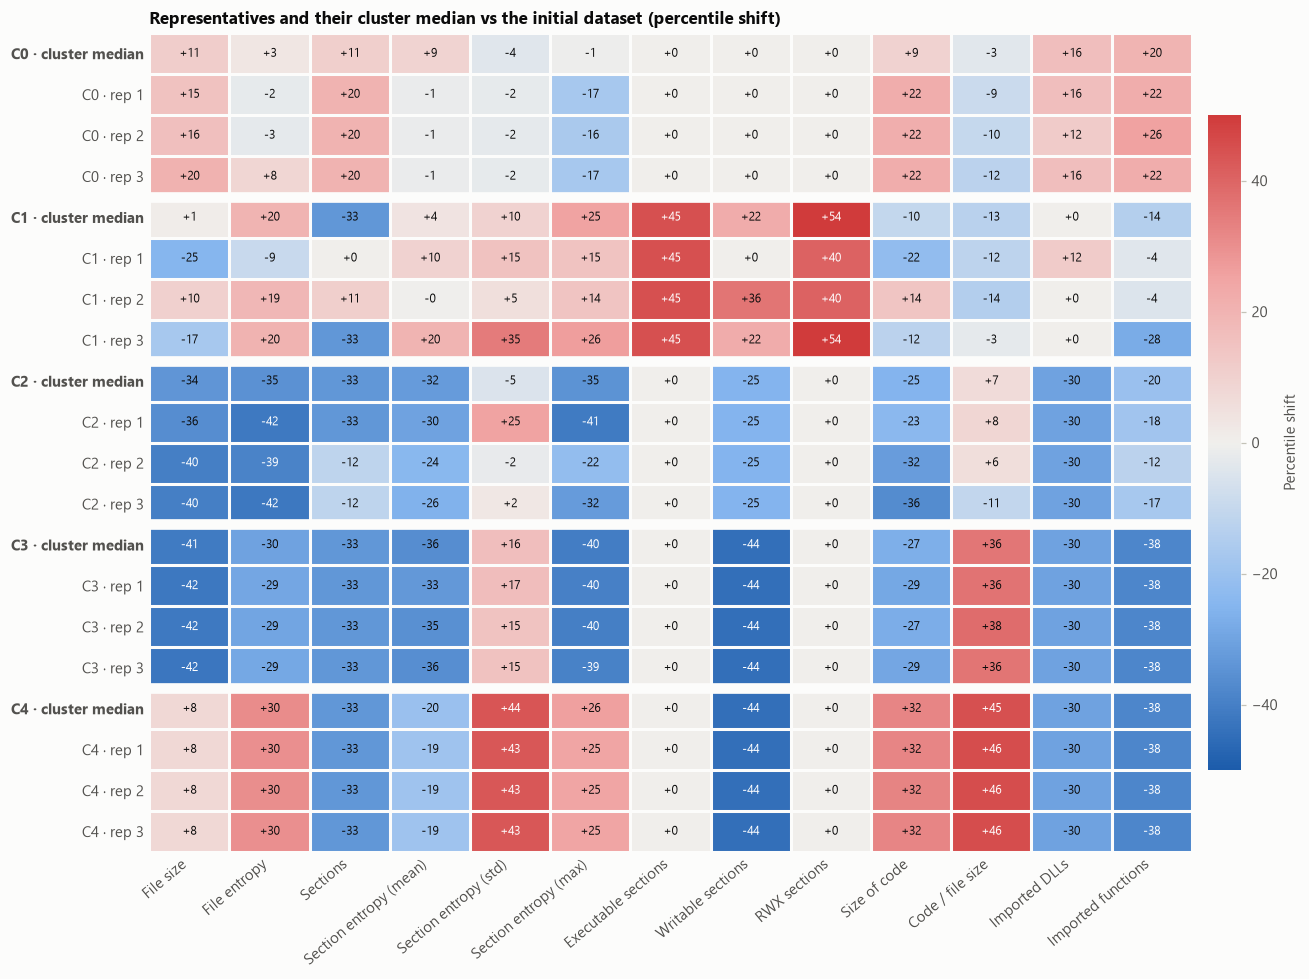

In [22]:
rep_values = representatives.set_index("label")[profile_columns].astype(float)
rep_shift = percentile_shift(rep_values)

blocks, block_labels = [], []
for cluster in cluster_ids:
    blocks.append(median_shift.loc[[cluster]])
    block_labels.append(f"C{cluster} · cluster median")
    cluster_rep_labels = picks.loc[picks["cluster"] == cluster, "label"]
    blocks.append(rep_shift.loc[cluster_rep_labels])
    block_labels.extend(cluster_rep_labels)

shift_table = pd.concat(blocks).rename(columns=PROFILE_FEATURES)
shift_table.index = block_labels

fig, ax = plt.subplots(figsize=(12, 0.34 * len(shift_table) + 2.2))
image = annotated_heatmap(ax, shift_table, DIVERGING, -50, 50, fmt="{:+.0f}")
rows_per_cluster = picks.groupby("cluster").size() + 1
for boundary in np.cumsum(rows_per_cluster.to_numpy())[:-1]:
    ax.axhline(boundary - 0.5, color=SURFACE, linewidth=7)
for tick, label in zip(ax.get_yticklabels(), block_labels):
    if label.endswith("cluster median"):
        tick.set_fontweight("bold")
ax.set_title("Representatives and their cluster median vs the initial dataset (percentile shift)")
colorbar = fig.colorbar(image, ax=ax, pad=0.015, fraction=0.03)
colorbar.outline.set_visible(False)
colorbar.set_label("Percentile shift", color=INK_2)
plt.tight_layout()
plt.show()

### 7.3 How representative are they?

For every representative, the share of the 13 profile features whose value lies inside the interquartile range (25th–75th percentile) of

- **its own cluster**: high means the sample is a typical member. The average over all members of the cluster is given as the reference level;
- **the initial dataset**: low means the sample, and hence the cluster, differs from the typical file of the dataset.

In [23]:
cluster_quartiles = model_df.groupby("cluster")[profile_columns].quantile([0.25, 0.75]).unstack()


def share_within(values, low, high):
    """Share of features whose value lies inside [low, high]."""
    return ((values >= low) & (values <= high)).mean(axis=1)


rows = []
for cluster in cluster_ids:
    low = cluster_quartiles.loc[cluster].xs(0.25, level=1)[profile_columns]
    high = cluster_quartiles.loc[cluster].xs(0.75, level=1)[profile_columns]
    members = model_df.loc[model_df["cluster"] == cluster, profile_columns]
    member_reference = share_within(members, low, high).mean()
    dominant_entry = model_df.loc[model_df["cluster"] == cluster, "entry_group"].mode().iat[0]

    for _, rep in representatives[representatives["cluster"] == cluster].iterrows():
        values = rep[profile_columns].astype(float).to_frame().T
        rows.append({
            "representative": rep["label"],
            "role": rep["role"],
            "within own cluster IQR": share_within(values, low, high).iat[0],
            "average member (reference)": member_reference,
            "within initial dataset IQR": share_within(
                values, dataset_quartiles.loc[0.25], dataset_quartiles.loc[0.75]).iat[0],
            "entry point": rep["EntryPointSection"],
            "matches cluster's dominant entry point": model_df.loc[rep["row_id"], "entry_group"] == dominant_entry,
        })

representativeness = pd.DataFrame(rows).set_index("representative")
display(representativeness.round(2))

,role,within own cluster IQR,average member (reference),within initial dataset IQR,entry point,matches cluster's dominant entry point
representative,,,,,,
C0 · rep 1,medoid,0.92,0.60,1.00,.text,True
C0 · rep 2,central #2,0.92,0.60,0.92,.text,True
C0 · rep 3,central #3,0.92,0.60,1.00,.text,True
C1 · rep 1,medoid,0.92,0.59,1.00,.text,True
C1 · rep 2,central #2,1.00,0.59,0.92,.text,True
C1 · rep 3,central #3,1.00,0.59,0.69,UPX1,False
C2 · rep 1,medoid,0.92,0.64,0.62,.text,True
C2 · rep 2,central #2,0.92,0.64,0.77,.text,True
C2 · rep 3,central #3,1.00,0.64,0.62,.text,True


In [24]:
# Optional: the raw text report of each cluster's first representative.
def show_source_report(source_file, max_lines=25):
    path = REPORT_DIR / source_file
    if not path.is_file():
        print(f"Report not found: {path}")
        return
    with path.open("r", encoding="utf-8", errors="replace") as report:
        for _, line in zip(range(max_lines), report):
            print("   ", line.rstrip())


if RAW_REPORT_LINES > 0:
    for _, rep in representatives[representatives["rank"] == 1].iterrows():
        print(f"\nCluster {rep['cluster']} – {rep['role']} – {rep['SourceFile']}")
        show_source_report(rep["SourceFile"], RAW_REPORT_LINES)
else:
    print("RAW_REPORT_LINES = 0, raw reports are not printed.")

RAW_REPORT_LINES = 0, raw reports are not printed.


## 8. Findings

### 8.1 Generated summary

The cell below writes the summary from the current results, so it stays correct when the options or the number of clusters change.

In [25]:
def describe_cluster(cluster):
    size = cluster_sizes[cluster]
    strongest = median_shift.loc[cluster].abs().nlargest(3).index
    traits = "; ".join(
        f"{PROFILE_FEATURES[column]} {'higher' if median_shift.loc[cluster, column] > 0 else 'lower'} "
        f"(median {format_number(cluster_median.loc[cluster, column])} vs {format_number(dataset_median[column])}, "
        f"{median_shift.loc[cluster, column]:+.0f} pts)"
        for column in strongest
    )
    entry_row = entry_share.loc[f"Cluster {cluster}"]
    first = representatives[(representatives["cluster"] == cluster) & (representatives["rank"] == 1)].iloc[0]
    typical = representativeness.loc[first["label"], "within own cluster IQR"]
    return (
        f"- **Cluster {cluster}** – {size:,} samples ({size / len(labels):.1%} of the clustered reports), "
        f"mean silhouette {silhouette_by_cluster[cluster]:.2f}. "
        f"Most distinctive: {traits}. "
        f"Dominant entry-point section `{entry_row.idxmax()}` ({entry_row.max():.0f}%). "
        f"First representative `{first['FileSHA256'][:16]}…` (CSV row {first['row_id']}) "
        f"lies inside the cluster IQR on {typical:.0%} of the features."
    )


summary_lines = [
    f"**Spectral clustering, k = {n_clusters}** on {len(labels):,} complete reports "
    f"({len(df) - len(labels):,} incomplete reports were not clustered).",
    "",
    f"- Silhouette {evaluation.loc['Silhouette (sample)', 'Spectral']:.3f} "
    f"(k-means baseline {evaluation.loc['Silhouette (sample)', 'K-means baseline']:.3f}), "
    f"Davies–Bouldin {evaluation.loc['Davies–Bouldin', 'Spectral']:.3f} "
    f"({evaluation.loc['Davies–Bouldin', 'K-means baseline']:.3f}), "
    f"Calinski–Harabasz {evaluation.loc['Calinski–Harabasz', 'Spectral']:,.0f} "
    f"({evaluation.loc['Calinski–Harabasz', 'K-means baseline']:,.0f}).",
    f"- Stability across landmark seeds: mean pairwise ARI "
    f"{evaluation.loc['Stability (mean pairwise ARI)', 'Spectral']:.3f}. "
    f"Agreement with k-means: ARI {agreement_ari:.3f}.",
    "",
    "Clusters, compared with the initial dataset (pts = percentile points from the dataset median):",
    "",
    *[describe_cluster(cluster) for cluster in cluster_ids],
]
display(Markdown("\n".join(summary_lines)))

**Spectral clustering, k = 5** on 36,657 complete reports (1,504 incomplete reports were not clustered).

- Silhouette 0.161 (k-means baseline 0.179), Davies–Bouldin 1.710 (1.714), Calinski–Harabasz 4,055 (6,185).
- Stability across landmark seeds: mean pairwise ARI 0.867. Agreement with k-means: ARI 0.506.

Clusters, compared with the initial dataset (pts = percentile points from the dataset median):

- **Cluster 0** – 18,002 samples (49.1% of the clustered reports), mean silhouette 0.27. Most distinctive: Imported functions higher (median 144 vs 89, +20 pts); Imported DLLs higher (median 7 vs 4, +16 pts); File size higher (median 1,043,398 vs 555,520, +11 pts). Dominant entry-point section `.text` (86%). First representative `bacf49519992d3ba…` (CSV row 28158) lies inside the cluster IQR on 92% of the features.
- **Cluster 1** – 11,472 samples (31.3% of the clustered reports), mean silhouette 0.02. Most distinctive: RWX sections higher (median 2 vs 0, +54 pts); Executable sections higher (median 2 vs 1, +45 pts); Sections lower (median 3 vs 5, -33 pts). Dominant entry-point section `.text` (36%). First representative `9fe5c55b6579c781…` (CSV row 23921) lies inside the cluster IQR on 92% of the features.
- **Cluster 2** – 4,896 samples (13.4% of the clustered reports), mean silhouette -0.16. Most distinctive: File entropy lower (median 4.882 vs 6.531, -35 pts); Section entropy (max) lower (median 5.808 vs 6.661, -35 pts); File size lower (median 92,646 vs 555,520, -34 pts). Dominant entry-point section `.text` (97%). First representative `7517af71ef65c561…` (CSV row 17418) lies inside the cluster IQR on 92% of the features.
- **Cluster 3** – 1,179 samples (3.2% of the clustered reports), mean silhouette 0.72. Most distinctive: Writable sections lower (median 0 vs 2, -44 pts); File size lower (median 45,056 vs 555,520, -41 pts); Section entropy (max) lower (median 5.603 vs 6.661, -40 pts). Dominant entry-point section `.text` (100%). First representative `45e4abd14a088e49…` (CSV row 10350) lies inside the cluster IQR on 100% of the features.
- **Cluster 4** – 1,108 samples (3.0% of the clustered reports), mean silhouette 0.67. Most distinctive: Code / file size higher (median 0.996 vs 0.427, +45 pts); Writable sections lower (median 0 vs 2, -44 pts); Section entropy (std) higher (median 3.124 vs 2.079, +44 pts). Dominant entry-point section `.text` (100%). First representative `00f7650db646dc56…` (CSV row 156) lies inside the cluster IQR on 100% of the features.

### 8.2 Interpretation

This text describes the run with the default configuration (`k = 5`, 2,000 landmarks, seed 42, three `central` representatives). If you change the options, the generated summary above is the up-to-date version and the numbers below will no longer match.

**How many clusters.** The eigengap is equally large after the 2nd and the 5th eigenvalue (0.063 each), and both partitions are stable across landmark seeds (ARI 0.95 and 0.87). `k = 5` is used because it is the finer of the two; `k = 4` is also stable (0.91) with a smaller gap. From `k = 7` on the stability drops below 0.65, so finer partitions are not reproducible with this feature set.

**What the clusters are.** The clusters separate build and packaging *types* rather than individual families:

| Cluster | Share of clustered reports | Reading | Evidence |
| --- | --- | --- | --- |
| 0 | 49.1% | Conventional native executables | Most sections (median 6) and imports (median 144 functions from 7 DLLs); entry point in `.text` (86%) or `CODE` (10%); only 5% have an RWX section; ordinary Win32 API imports such as `CloseHandle` in 85% of the files against 26% elsewhere. |
| 1 | 31.3% | Packed or self-modifying executables | 88% have at least one RWX section (dataset: 29%), 53% have file entropy ≥ 7 (dataset: 33%), and the entry point is outside `.text` in 64% of the files (`UPX1` 25%, `UPX0` 11%, rare names 19%). |
| 2 | 13.4% | Small, low-entropy executables, a mixed group | Median size 93 KB against 556 KB, median entropy 4.9 against 6.5, few imports (median 17). It mixes Visual Basic runtime imports (about 20%), .NET stubs (27%) and other small files. |
| 3 | 3.2% | Small plain .NET assemblies | 100% of the files import nothing but the .NET stub (`_CorExeMain` 62%, `_CorDllMain` 38%); median size 45 KB; median of 0 writable sections; 0% have entropy ≥ 7. |
| 4 | 3.0% | Large, high-entropy .NET assemblies | 100% of the files (rounded) import nothing but the .NET stub (`_CorExeMain` in 98%); median size 847 KB; 82% have entropy ≥ 7 and the median `SizeOfCode` is 99.6% of the file size, which is consistent with a packed or encrypted payload inside the assembly. |

The import *names* were not part of the distance (only the import count was), yet clusters 3 and 4 turn out to be 100% .NET. That is independent support that the partition follows real structure and not only the scaling of the features.

**Quality.** The picture is mixed, and it differs strongly between clusters:

- Clusters 3 and 4 are compact and well separated (silhouette 0.72 and 0.67, practically no sample with a negative value).
- Cluster 0 is acceptable (0.27). Cluster 1 overlaps its neighbours (0.02; 35% of its sampled members have a negative silhouette, and its nearest cluster is cluster 0).
- Cluster 2 is the weak one: silhouette −0.16, 82% of its sampled members have a negative silhouette, and its nearest cluster is cluster 3. It works as a catch-all for small files and should be read as "what is left" rather than as one coherent group.
- Overall, spectral clustering does not beat the k-means baseline on the internal metrics: silhouette 0.161 against 0.179, Calinski–Harabasz 4,055 against 6,185, Davies–Bouldin equal (1.71), stability 0.87 against 0.89. These metrics favour the round clusters k-means is built to find, so a lower score was expected, but it also means there is no numerical evidence here that the spectral partition is the better one.
- The two methods agree only moderately (ARI 0.51). The difference is informative: k-means splits the conventional executables (cluster 0) into two groups and merges the small .NET files (cluster 3) with most of cluster 2, while spectral clustering keeps cluster 0 together and isolates both .NET groups.

**What the remapped representatives show.**

- The representatives are typical for their clusters: 92–100% of their feature values fall inside the cluster's interquartile range, against 59–76% for an average member.
- Cluster 0 is the "typical file" of the dataset. Its representatives also sit inside the *dataset's* interquartile range on 92–100% of the features, and the dataset medians are largely driven by this half of the data.
- Clusters 3 and 4 are the least like the dataset as a whole: their representatives fall inside the dataset's interquartile range on only 38% and 54% of the features. Their three representatives are almost interchangeable (cluster 4: 847–852 KB, entropy 7.64, one import), which points to very homogeneous groups, possibly files produced by the same builder.
- Clusters 1 and 2 are heterogeneous, so a medoid alone under-describes them. In cluster 1 the medoid is a `.text`-entry file with one RWX section, while the third representative is a UPX-packed file with sections `UPX1, UPX2` and seven imports. For these two clusters `REPRESENTATIVE_METHOD = "diverse"` gives a more honest picture.
- 1,504 reports (3.9% of the initial dataset) are not clustered at all, almost all of them because the report has no entry-point section.

**Limits.** There are no family labels, so the evaluation is internal only: it measures how well separated the groups are, not whether they match malware families. The landmark approximation makes every sample inherit the cluster of its nearest landmark, which blurs cluster borders slightly. The natural next steps are to sub-cluster clusters 1 and 2, to add features built from the import names, and to compute ARI or NMI against family labels if such labels become available.

## 9. Optional: save the cluster assignments

Set `SAVE_ASSIGNMENTS = True` to write one row per report of the initial dataset with its cluster (`-1` for reports that were not clustered).

In [26]:
SAVE_ASSIGNMENTS = False
ASSIGNMENT_PATH = Path.cwd() / "result" / "data2_spectral_clusters.csv"

if SAVE_ASSIGNMENTS:
    output = df[["SourceFile", "FileSHA256"]].copy()
    output["cluster"] = -1
    output.loc[model_df.index, "cluster"] = labels
    output["is_representative"] = output.index.isin(representatives["row_id"])
    output.to_csv(ASSIGNMENT_PATH, index=False)
    print(f"Saved {len(output):,} rows to {ASSIGNMENT_PATH}")
else:
    print("SAVE_ASSIGNMENTS is False, nothing written.")

SAVE_ASSIGNMENTS is False, nothing written.
